# 6. ✨ Place a transparent AR overlay

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/6-image-compositing.ipynb)

## Goal

Blend a transparent sticker onto a rectangular or tilted region. By the end, you can explain alpha, choose a placement region and combine the overlay with a mask.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.1 if needed. A CPU is enough. Python 3.10+ is supported; no model downloads are needed here.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.1':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.1'])
import numpy as np
from landpy import ImageLand, SquareMarks, QuadMarks, Filter, Debugger


## Steps

### 1. Make a transparent image overlay

Alpha is a separate uint8 channel. A value of 0 is transparent, 255 is opaque. The blend ratio multiplies source alpha.

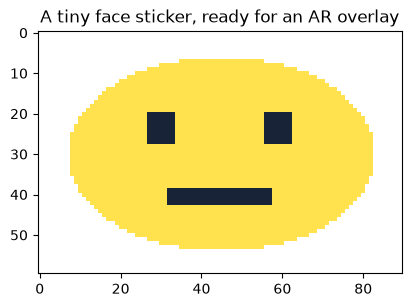

In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

sticker = np.zeros((60, 90, 4), dtype=np.uint8)
y, x = np.indices(sticker.shape[:2])
inside = ((y-30)/24)**2 + ((x-45)/38)**2 < 1
sticker[inside] = [255, 220, 40, 210]

sticker[20:28, 27:34] = [25, 35, 55, 255]
sticker[20:28, 56:63] = [25, 35, 55, 255]
sticker[39:43, 32:58] = [25, 35, 55, 255]
ImageLand(sticker).show('A tiny face sticker, ready for an AR overlay');

### 2. Position an overlay

`src_land` names the destination region on the base image; `plant_land` selects the source region on the overlay. This historical naming is retained. Both accept rectangles or convex quads. The source image is unchanged.

The checker is simple: the sticker should tilt with the quad, and the canvas should remain visible through its translucent yellow fill. This is placement on one image; a live AR application would update the region for each frame.

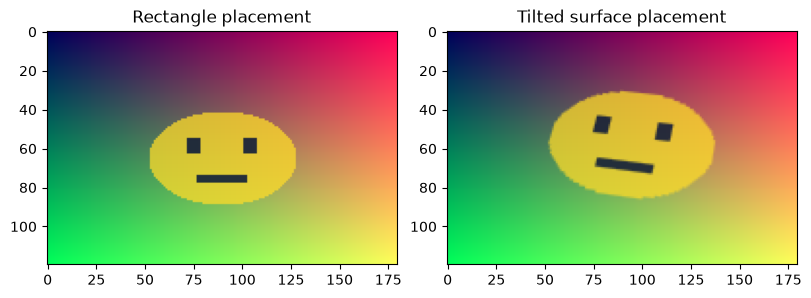

In [3]:
region = SquareMarks(35, 95, 45, 135, shape=image.shape)
placed = image.copy().implant_image(sticker, src_land=region, ratio=.9)
quad = QuadMarks((20, 55), (30, 150), (100, 140), (85, 35), shape=image.shape)
perspective = image.copy().implant_image(sticker, src_land=quad, ratio=.9)
debugger = Debugger(visual_debug=True)
debugger.log_images(
    [placed.get_image(), perspective.get_image()],
    ['Rectangle placement', 'Tilted surface placement'],
    [Debugger.LogTypes.IMAGE] * 2,
);

### 3. Compose with existing masks

Use landmark polygons to build a HeatLand and apply a color filter before compositing. The same workflow fits detected face regions in tutorial 8.

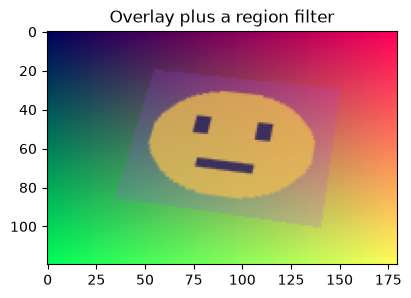

In [4]:
mask = quad.to_heat(.6)
result = perspective.copy().implant_filter(Filter('#aa44ff', .3), mask)
result.show('Overlay plus a region filter');

## Checks

In [5]:
assert result.shape == image.shape
assert image.mode == 'RGB'
np.testing.assert_array_equal(placed.get_image()[0, 0], image.get_image()[0, 0])
np.testing.assert_array_equal(image.copy().implant_image(sticker, ratio=0).get_image(), image.get_image())

## Take it further 🚀

Your overlay is ready. Notebook 7 explains model wrappers; notebook 8 uses real face predictions to choose the placement.

[Choose the next notebook](https://github.com/bateni1380/landpy/tree/master/tutorials)

**Try it:** Lower the overlay ratio to 0.3. Can you see the background through it?

➡️ **[Continue to notebook 7](https://github.com/bateni1380/landpy/blob/master/tutorials/7-model-wrappers.ipynb)**

[← Previous lesson](https://github.com/bateni1380/landpy/blob/master/tutorials/5-crops-and-perspective.ipynb)